# Logistic Regression Optimisation: A Fair Comparison of the Original and Feature-Engineered Models



This notebook compares two sub-models under exactly the same data split, five-fold stratified cross-validation, and evaluation protocol:

1. **Original model**: uses only the original variables (excluding `PageValues`);
2. **Feature-engineered model**: adds session-depth, product-engagement, exit-behaviour, and conditional-interaction variables. Winsorisation, transformation, and regularisation selection are performed within each training fold.

New variables should not be evaluated from a correlation plot alone. This notebook examines variable redundancy, descriptive relationships with purchase outcomes, the stability of five-fold CV performance, and overall OOF curves. A held-out test set that never participates in model selection is used for the final check.


## 1. Design principles

- Training set: `online_shoppers_train_fixed.csv`; test set: `online_shoppers_test_fixed.csv`.
- The notebook runs when it and the two CSV files are placed in the same folder; no absolute paths are required.
- The random seed is fixed at **6805** and five-fold stratified cross-validation is used.
- Both sub-models exclude `PageValues`. It may reflect information from very near the conversion event, creating a risk that it is unavailable at prediction time or leaks information.
- **PR-AUC (average precision)** is the main tuning metric because purchase sessions are relatively rare. The decision threshold is selected by maximising F1 on training-set OOF predictions and is then fixed for the test set.
- All operations that learn data distributions (Winsorisation bounds, scaling, and encoding) are encapsulated in the Pipeline and fitted only on the relevant training fold.


In [ ]:
from pathlib import Path

SEED = 6805
DATA_DIR = Path.cwd().resolve()
TRAIN_PATH = DATA_DIR / "online_shoppers_train_fixed.csv"
TEST_PATH = DATA_DIR / "online_shoppers_test_fixed.csv"
RESULTS_DIR = DATA_DIR / "lr_dual_model_comparison_results"

missing = [path.name for path in (TRAIN_PATH, TEST_PATH) if not path.exists()]
if missing:
    raise FileNotFoundError("data path" + ", ".join(missing))
print(f"file：{DATA_DIR}")


file：C:\Users\王柄尧\OneDrive\桌面\logistic reg


## 2. New variables and preprocessing

| Variable group | New variables | Meaning |
|---|---|---|
| Session depth | `TotalPages`, `TotalDuration` | Total number of pages viewed and total time spent in the session |
| Product engagement | `ProductPageShare`, `ProductDurationShare`, `AvgProductDuration` | Share of product pages or product-page time, and average time spent per product page |
| Page behaviour | `AvgAdministrativeDuration`, `AvgInformationalDuration` | Average time spent on administrative and informational pages |
| Exit signals | `ExitMinusBounce`, `ExitBounceRatio` | Absolute difference and relative relationship between exit rate and bounce rate |
| Behaviour interactions | `MonthWeekend`, `HasAdministrative`, `HasInformational` | Month-by-weekend combination, and indicators for visits to the corresponding page category |

The feature-engineered model winsorises numeric variables at the **1st and 99th percentiles within each training fold** to reduce the influence of extreme sessions on logistic-regression coefficients. Count and duration variables are transformed using `log1p`, followed by a comparison of L1 and L2 regularisation. L1 can shrink coefficients of variables with no additional predictive contribution to zero.


In [2]:
"""Leakage-aware original-versus-feature-engineered logistic-regression study.

The module is deliberately self-contained so it can be embedded in a portable
notebook.  All transformations that learn from data live inside sklearn
pipelines, so cross-validation never sees validation-fold information.
"""

from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


SEED = 6805
TARGET = "Revenue"
RAW_NUMERIC = [
    "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "SpecialDay",
]
RAW_CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
LOG_COLUMNS_BASE = [
    "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
]
DERIVED_NUMERIC = [
    "TotalPages", "TotalDuration", "ProductPageShare", "ProductDurationShare",
    "AvgProductDuration", "AvgAdministrativeDuration", "AvgInformationalDuration",
    "ExitMinusBounce", "ExitBounceRatio",
]
DERIVED_CATEGORICAL = ["MonthWeekend", "HasAdministrative", "HasInformational"]
LOG_COLUMNS_ENGINEERED = LOG_COLUMNS_BASE + [
    "TotalPages", "TotalDuration", "AvgProductDuration", "AvgAdministrativeDuration", "AvgInformationalDuration",
]


class SessionFeatureEngineer(BaseEstimator, TransformerMixin):
    """Construct behavioural variables using only predictors available in-session."""

    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, x, y=None):
        return self

    def transform(self, x):
        frame = x.copy()
        if not self.enabled:
            return frame
        total_pages = frame["Administrative"] + frame["Informational"] + frame["ProductRelated"]
        total_duration = frame["Administrative_Duration"] + frame["Informational_Duration"] + frame["ProductRelated_Duration"]
        frame["TotalPages"] = total_pages
        frame["TotalDuration"] = total_duration
        frame["ProductPageShare"] = frame["ProductRelated"] / (total_pages + 1.0)
        frame["ProductDurationShare"] = frame["ProductRelated_Duration"] / (total_duration + 1.0)
        frame["AvgProductDuration"] = frame["ProductRelated_Duration"] / (frame["ProductRelated"] + 1.0)
        frame["AvgAdministrativeDuration"] = frame["Administrative_Duration"] / (frame["Administrative"] + 1.0)
        frame["AvgInformationalDuration"] = frame["Informational_Duration"] / (frame["Informational"] + 1.0)
        frame["ExitMinusBounce"] = frame["ExitRates"] - frame["BounceRates"]
        frame["ExitBounceRatio"] = frame["ExitRates"] / (frame["BounceRates"] + 0.001)
        frame["MonthWeekend"] = frame["Month"].astype(str) + "_" + frame["Weekend"].astype(str)
        frame["HasAdministrative"] = np.where(frame["Administrative"] > 0, "Yes", "No")
        frame["HasInformational"] = np.where(frame["Informational"] > 0, "Yes", "No")
        return frame


class Winsorizer(BaseEstimator, TransformerMixin):
    """Fold-local clipping at the 1st and 99th percentiles."""

    def __init__(self, columns, lower=0.01, upper=0.99):
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, x, y=None):
        self.lower_bounds_ = x[self.columns].quantile(self.lower)
        self.upper_bounds_ = x[self.columns].quantile(self.upper)
        return self

    def transform(self, x):
        frame = x.copy()
        for column in self.columns:
            frame[column] = frame[column].clip(self.lower_bounds_[column], self.upper_bounds_[column])
        return frame


class Log1pSelected(BaseEstimator, TransformerMixin):
    """Log-transform only explicitly named non-negative long-tailed columns."""

    def __init__(self, columns):
        self.columns = columns

    def fit(self, x, y=None):
        return self

    def transform(self, x):
        frame = x.copy()
        for column in self.columns:
            frame[column] = np.log1p(frame[column].astype(float))
        return frame


def make_pipeline(engineered, penalty="l2"):
    numeric = RAW_NUMERIC + (DERIVED_NUMERIC if engineered else [])
    categorical = RAW_CATEGORICAL + (DERIVED_CATEGORICAL if engineered else [])
    log_columns = LOG_COLUMNS_ENGINEERED if engineered else LOG_COLUMNS_BASE
    preprocessor = ColumnTransformer(
        [
            ("numeric", Pipeline([("log1p", Log1pSelected(log_columns)), ("scale", StandardScaler())]), numeric),
            ("categorical", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    steps = [("features", SessionFeatureEngineer(enabled=engineered))]
    if engineered:
        steps.append(("winsor", Winsorizer(numeric)))
    steps.extend(
        [
            ("preprocess", preprocessor),
            ("model", LogisticRegression(
                penalty=penalty, solver="liblinear", class_weight="balanced", max_iter=5000, random_state=SEED,
            )),
        ]
    )
    return Pipeline(steps)


def find_oof_threshold(estimator, x, y, cv):
    probabilities = cross_val_predict(clone(estimator), x, y, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    thresholds = np.linspace(0.05, 0.95, 901)
    f1_values = np.array([f1_score(y, probabilities >= threshold, zero_division=0) for threshold in thresholds])
    best_index = int(f1_values.argmax())
    return float(thresholds[best_index]), float(f1_values[best_index]), probabilities


def evaluate(y, probabilities, threshold):
    labels = probabilities >= threshold
    actual = np.asarray(y)
    return {
        "threshold": round(float(threshold), 3),
        "roc_auc": round(float(roc_auc_score(y, probabilities)), 4),
        "pr_auc": round(float(average_precision_score(y, probabilities)), 4),
        "precision": round(float(precision_score(y, labels, zero_division=0)), 4),
        "recall": round(float(recall_score(y, labels, zero_division=0)), 4),
        "f1": round(float(f1_score(y, labels, zero_division=0)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y, labels)), 4),
        "tn": int(((labels == 0) & (actual == 0)).sum()),
        "fp": int(((labels == 1) & (actual == 0)).sum()),
        "fn": int(((labels == 0) & (actual == 1)).sum()),
        "tp": int(((labels == 1) & (actual == 1)).sum()),
    }


def run_specification(name, estimator, param_grid, x_train, y_train, x_test, y_test, cv):
    grid = GridSearchCV(estimator, param_grid, scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    grid.fit(x_train, y_train)
    threshold, oof_f1, oof_probabilities = find_oof_threshold(grid.best_estimator_, x_train, y_train, cv)
    final = clone(grid.best_estimator_).fit(x_train, y_train)
    test_probabilities = final.predict_proba(x_test)[:, 1]
    fold_scores = cross_validate(
        clone(grid.best_estimator_), x_train, y_train, cv=cv, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=1,
    )
    return {
        "name": name,
        "grid": grid,
        "final": final,
        "threshold": threshold,
        "oof_f1": oof_f1,
        "oof_probabilities": oof_probabilities,
        "test_probabilities": test_probabilities,
        "test_metrics": evaluate(y_test, test_probabilities, threshold),
        "fold_pr_auc": fold_scores["test_pr_auc"],
        "fold_roc_auc": fold_scores["test_roc_auc"],
    }


def engineered_frame(x):
    return SessionFeatureEngineer(enabled=True).fit_transform(x)


def plot_feature_diagnostics(x_train, y_train, baseline, engineered, results_dir):
    """Create interpretable, complementary evidence rather than one decorative heatmap."""
    sns.set_theme(style="whitegrid", context="notebook")
    frame = engineered_frame(x_train)

    # 1) Correlation with source variables: redundancy, not predictive value.
    corr_columns = ["ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates"] + DERIVED_NUMERIC
    corr = frame[corr_columns].corr()
    fig, ax = plt.subplots(figsize=(11, 8.4))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=.35, cbar_kws={"label": "Pearson correlation"}, ax=ax)
    ax.set_title("Correlation of original and engineered numeric features\n(used to flag redundancy, not predictive value)")
    fig.tight_layout()
    fig.savefig(results_dir / "01_engineered_feature_correlation.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    # 2) Purchase rate across quantiles: direct descriptive association with target.
    selected = ["TotalDuration", "ProductPageShare", "AvgProductDuration", "ExitMinusBounce"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharey=True)
    for ax, column in zip(axes.ravel(), selected):
        tmp = pd.DataFrame({column: frame[column], TARGET: np.asarray(y_train)})
        tmp["quintile"] = pd.qcut(tmp[column].rank(method="first"), q=5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
        rates = tmp.groupby("quintile", observed=False)[TARGET].mean().mul(100)
        bars = ax.bar(rates.index.astype(str), rates.values, color="#d35400")
        ax.bar_label(bars, labels=[f"{value:.1f}%" for value in rates.values], padding=3, fontsize=9)
        ax.axhline(np.asarray(y_train).mean() * 100, color="#3d3d3d", linestyle="--", linewidth=1, label="Training average")
        ax.set_title(column)
        ax.set_xlabel("")
        ax.set_ylabel("Purchase rate (%)")
        ax.tick_params(axis="x", rotation=20)
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.suptitle("Do engineered variables separate purchasing behaviour?\nTraining-set descriptive view; not a causal estimate", y=1.02, fontsize=14)
    fig.tight_layout()
    fig.savefig(results_dir / "02_engineered_feature_purchase_rates.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    # 3) Paired CV fold view: stability of the PR-AUC change.
    folds = np.arange(1, len(baseline["fold_pr_auc"]) + 1)
    fig, ax = plt.subplots(figsize=(8.6, 4.8))
    ax.plot(folds, baseline["fold_pr_auc"], marker="o", linewidth=2, color="#1f4e78", label="Original LR")
    ax.plot(folds, engineered["fold_pr_auc"], marker="o", linewidth=2, color="#d35400", label="Engineered LR")
    for fold, base, eng in zip(folds, baseline["fold_pr_auc"], engineered["fold_pr_auc"]):
        ax.vlines(fold, min(base, eng), max(base, eng), color="#9a9a9a", linewidth=1)
    ax.set_xticks(folds)
    ax.set_xlabel("Stratified CV fold (same seed and folds)")
    ax.set_ylabel("PR-AUC / average precision")
    ax.set_title("Five-fold CV PR-AUC: stability of feature-engineering gain")
    ax.legend()
    fig.tight_layout()
    fig.savefig(results_dir / "03_cv_pr_auc_by_fold.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    # 4) Held-out model comparison, independent of threshold.
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for label, result, color in [("Original LR", baseline, "#1f4e78"), ("Engineered LR", engineered, "#d35400")]:
        RocCurveDisplay.from_predictions(y_train.iloc[:0] if False else np.asarray(y_train), result["oof_probabilities"], name=f"{label} OOF", ax=axes[0], color=color)
        PrecisionRecallDisplay.from_predictions(np.asarray(y_train), result["oof_probabilities"], name=f"{label} OOF", ax=axes[1], color=color)
    axes[0].set_title("OOF ROC curves (training only)")
    axes[1].axhline(np.asarray(y_train).mean(), color="gray", linestyle="--", linewidth=1, label=f"Positive rate = {np.asarray(y_train).mean():.1%}")
    axes[1].set_title("OOF precision–recall curves (training only)")
    axes[1].legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    fig.savefig(results_dir / "04_oof_model_curves.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def run_study(data_dir, results_dir):
    data_dir = Path(data_dir).resolve()
    results_dir = Path(results_dir).resolve()
    results_dir.mkdir(parents=True, exist_ok=True)
    train = pd.read_csv(data_dir / "online_shoppers_train_fixed.csv")
    test = pd.read_csv(data_dir / "online_shoppers_test_fixed.csv")
    x_train = train.drop(columns=[TARGET, "PageValues"])
    y_train = train[TARGET].astype(int)
    x_test = test.drop(columns=[TARGET, "PageValues"])
    y_test = test[TARGET].astype(int)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    baseline = run_specification(
        "Original L2 logistic regression", make_pipeline(False),
        {"model__C": [0.01, 0.1, 1.0, 10.0, 100.0]}, x_train, y_train, x_test, y_test, cv,
    )
    engineered = run_specification(
        "Feature-engineered logistic regression", make_pipeline(True),
        {"model__penalty": ["l1", "l2"], "model__C": [0.005, 0.01, 0.05, 0.1, 0.5, 1.0]},
        x_train, y_train, x_test, y_test, cv,
    )

    comparison = pd.DataFrame(
        [baseline["test_metrics"], engineered["test_metrics"]],
        index=["Original LR", "Engineered LR"],
    )
    comparison["cv_pr_auc"] = [baseline["grid"].best_score_, engineered["grid"].best_score_]
    comparison["oof_f1"] = [baseline["oof_f1"], engineered["oof_f1"]]
    comparison.to_csv(results_dir / "model_comparison.csv", encoding="utf-8-sig")
    pd.DataFrame({"fold": range(1, 6), "original_lr_pr_auc": baseline["fold_pr_auc"], "engineered_lr_pr_auc": engineered["fold_pr_auc"]}).to_csv(results_dir / "cv_fold_pr_auc.csv", index=False, encoding="utf-8-sig")
    plot_feature_diagnostics(x_train, y_train, baseline, engineered, results_dir)

    summary = {
        "seed": SEED,
        "data_policy": "Both models exclude PageValues because it may leak near-conversion information.",
        "feature_engineering": {
            "winsorisation": "1st/99th percentile bounds are fitted within each training fold only.",
            "new_numeric_features": DERIVED_NUMERIC,
            "new_categorical_features": DERIVED_CATEGORICAL,
        },
        "original_lr": {"best_params": baseline["grid"].best_params_, "cv_pr_auc": baseline["grid"].best_score_, "oof_f1": baseline["oof_f1"], "test": baseline["test_metrics"]},
        "engineered_lr": {"best_params": engineered["grid"].best_params_, "cv_pr_auc": engineered["grid"].best_score_, "oof_f1": engineered["oof_f1"], "test": engineered["test_metrics"]},
    }
    (results_dir / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    return {"summary": summary, "comparison": comparison, "baseline": baseline, "engineered": engineered, "x_train": x_train, "y_train": y_train}



## 3. Train the two sub-models

Both models select hyperparameters using PR-AUC. The test set does not participate in feature selection, regularisation selection, or threshold selection.


In [3]:
study = run_study(DATA_DIR, RESULTS_DIR)
summary = study["summary"]
comparison = study["comparison"].copy()

display_columns = ["cv_pr_auc", "roc_auc", "pr_auc", "threshold", "precision", "recall", "f1", "balanced_accuracy", "tp", "fp", "fn", "tn"]
comparison[display_columns].round(4)


e:\Python\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
e:\Python\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [2, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
e:\Python\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
e:\Python\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [2, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
e:\Python\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [4] during transform. These unknown c

,cv_pr_auc,roc_auc,pr_auc,threshold,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
Original LR,0.3398,0.7564,0.3351,0.557,0.2989,0.6361,0.4067,0.6796,243,570,139,1489
Engineered LR,0.3424,0.7615,0.3426,0.587,0.3081,0.5864,0.4040,0.6710,224,503,158,1556


## 4. Figure 1: Are the new variables merely duplicates of the original variables?

The heatmap is used to screen for redundancy and multicollinearity: variables with a high absolute correlation may contain similar information, making logistic-regression coefficients less stable to interpret. It **cannot directly prove** that a variable predicts purchase; therefore, the purchase-rate plot, five-fold PR-AUC comparison, and OOF curves below are also needed.


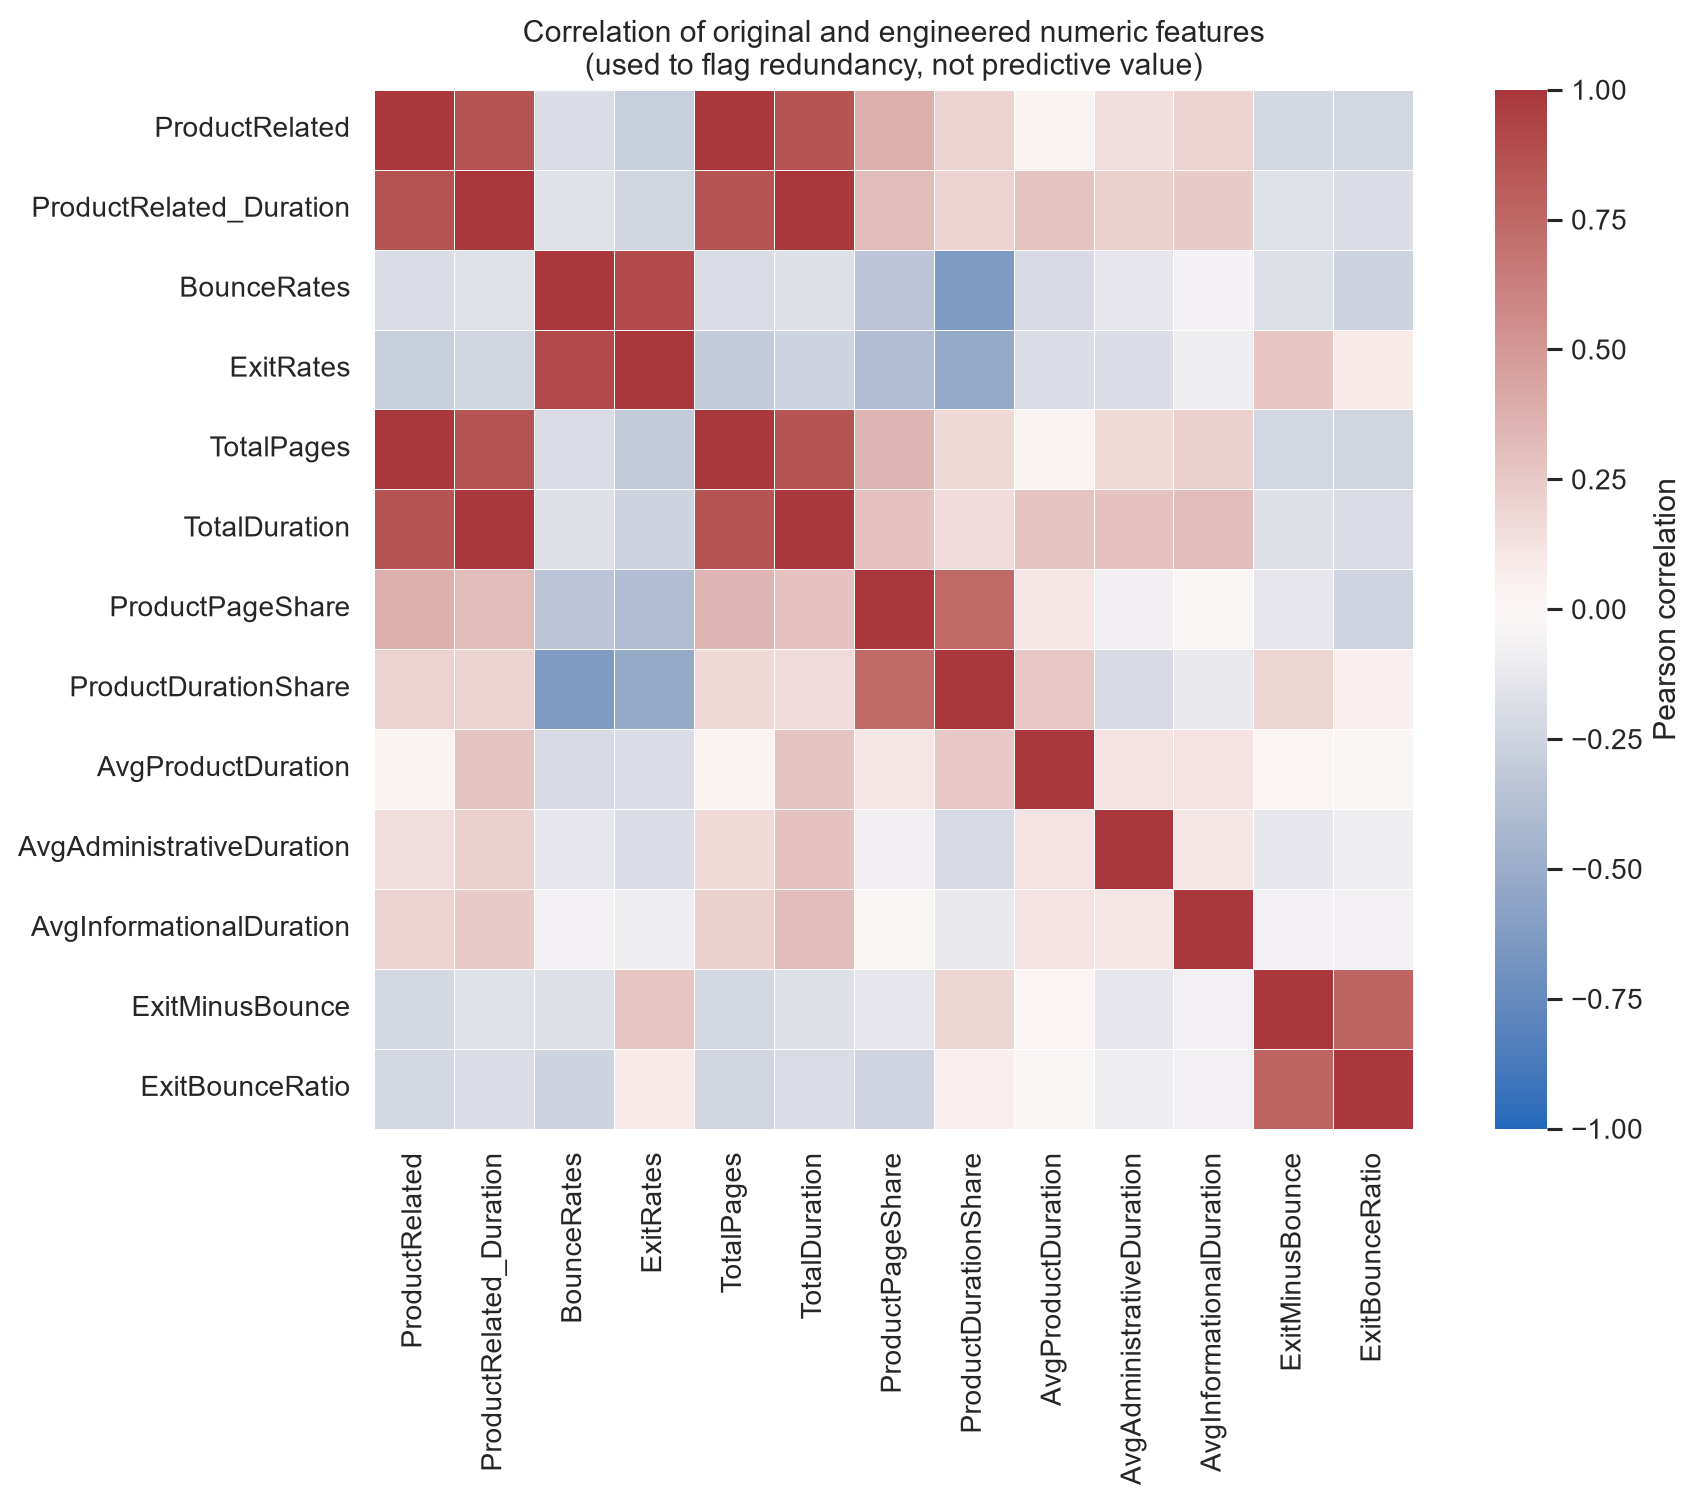

In [4]:
from IPython.display import Image, display

display(Image(filename=str(RESULTS_DIR / "01_engineered_feature_correlation.png")))


## 5. Figure 2: Are the new variables associated with purchase behaviour?

The figure divides training observations into five groups according to the values of a new variable and shows the observed purchase rate in each group. It is **descriptive evidence**: a clear gradient suggests that the variable contains purchase-related information, but it does not establish causality or prove an independent contribution after controlling for other variables.


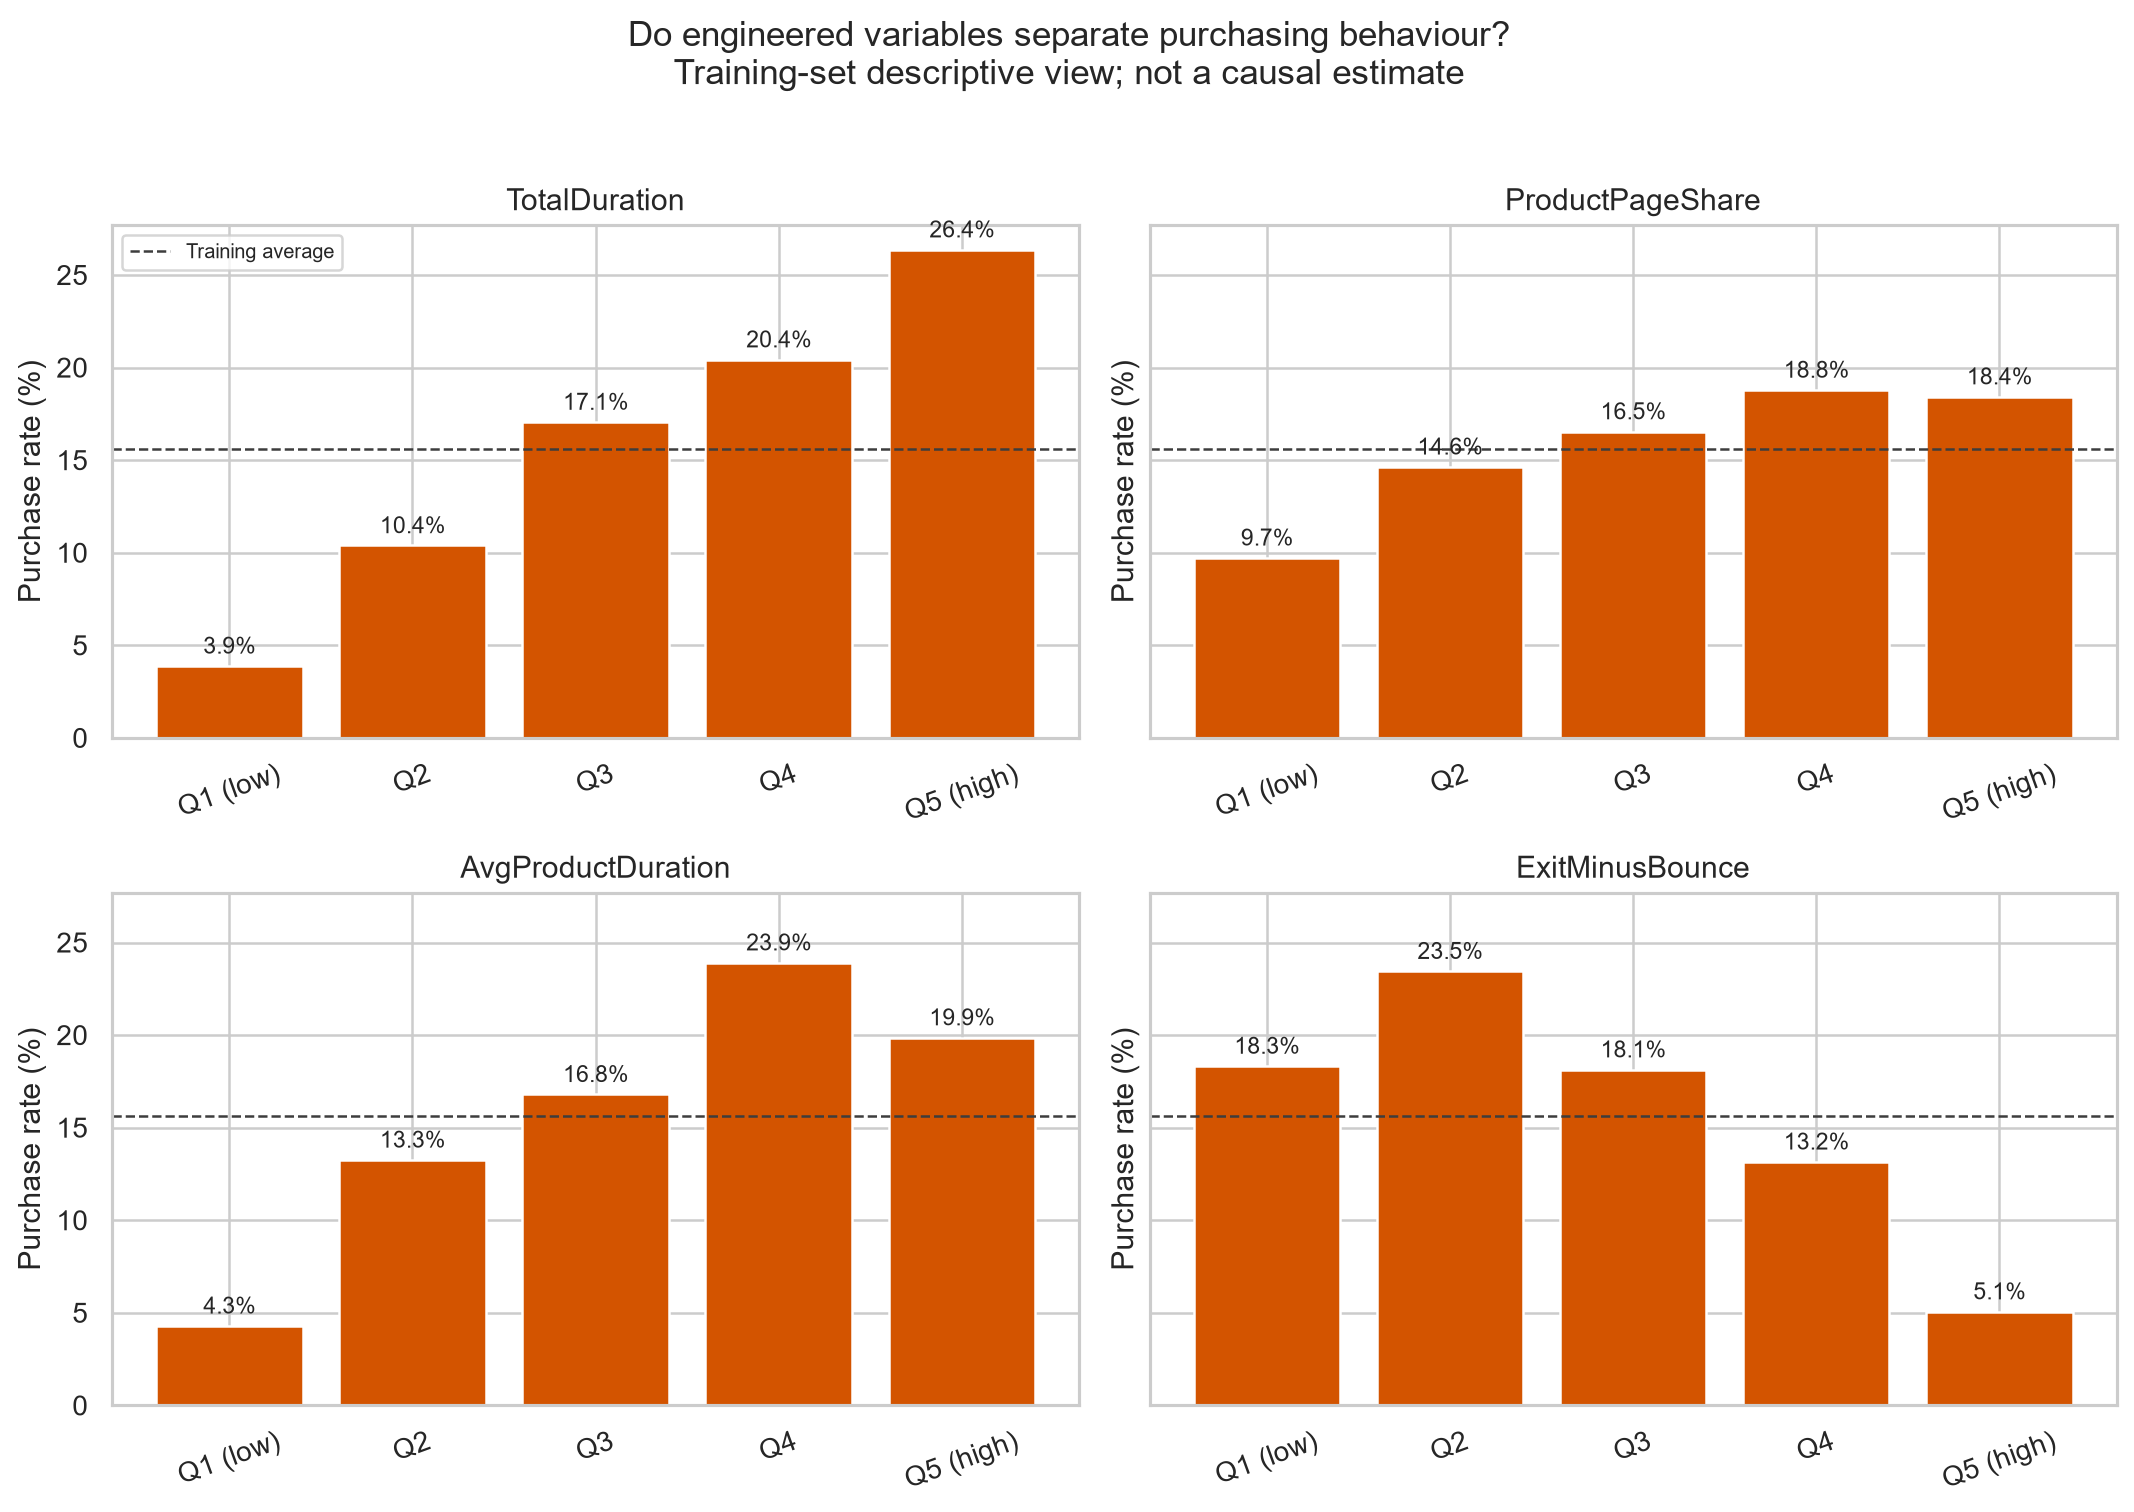

In [5]:
display(Image(filename=str(RESULTS_DIR / "02_engineered_feature_purchase_rates.png")))


## 6. Figure 3: Is the improvement stable?

All five folds use the same random split. If the feature-engineered model has PR-AUC no lower than the original model in most folds, its improvement is more credible; if it is substantially higher in only one or two folds, the average improvement should be interpreted cautiously.


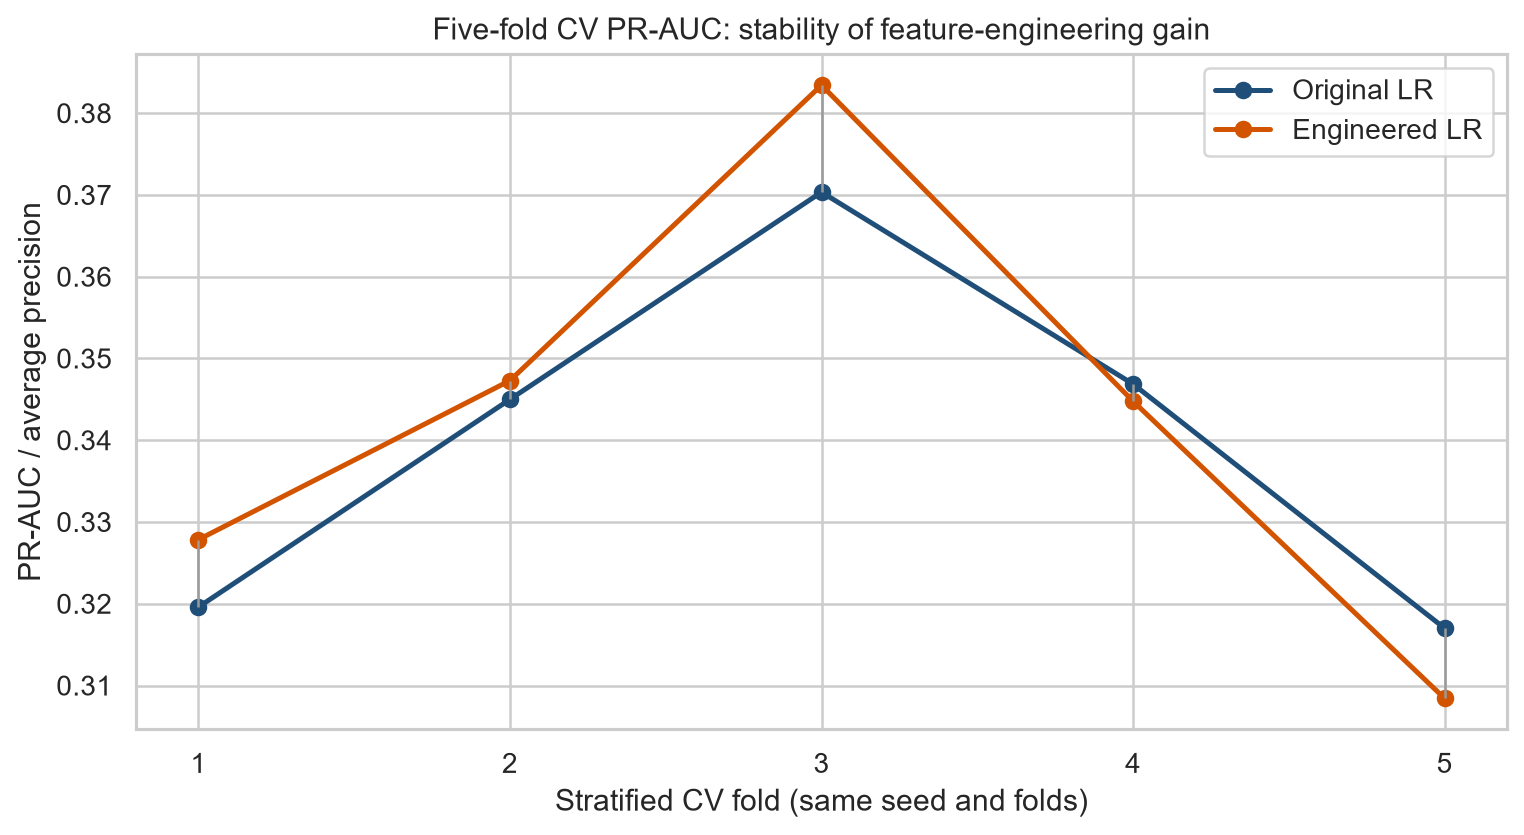

,fold,original_lr_pr_auc,engineered_lr_pr_auc,difference_engineered_minus_original
0,1,0.3196,0.3278,0.0083
1,2,0.3450,0.3473,0.0023
2,3,0.3703,0.3834,0.0131
3,4,0.3469,0.3448,-0.0021
4,5,0.3170,0.3084,-0.0086


In [6]:
display(Image(filename=str(RESULTS_DIR / "03_cv_pr_auc_by_fold.png")))

fold_comparison = pd.read_csv(RESULTS_DIR / "cv_fold_pr_auc.csv")
fold_comparison["difference_engineered_minus_original"] = fold_comparison["engineered_lr_pr_auc"] - fold_comparison["original_lr_pr_auc"]
fold_comparison.round(4)


## 7. Figure 4: Overall ranking ability of the two models

The OOF curves use predictions made for each training observation by a model that did not see that observation during fitting, making them more credible than in-sample fitted curves. The PR curve is more aligned with the minority-purchaser identification problem, while the ROC curve is a supplementary overall ranking metric.


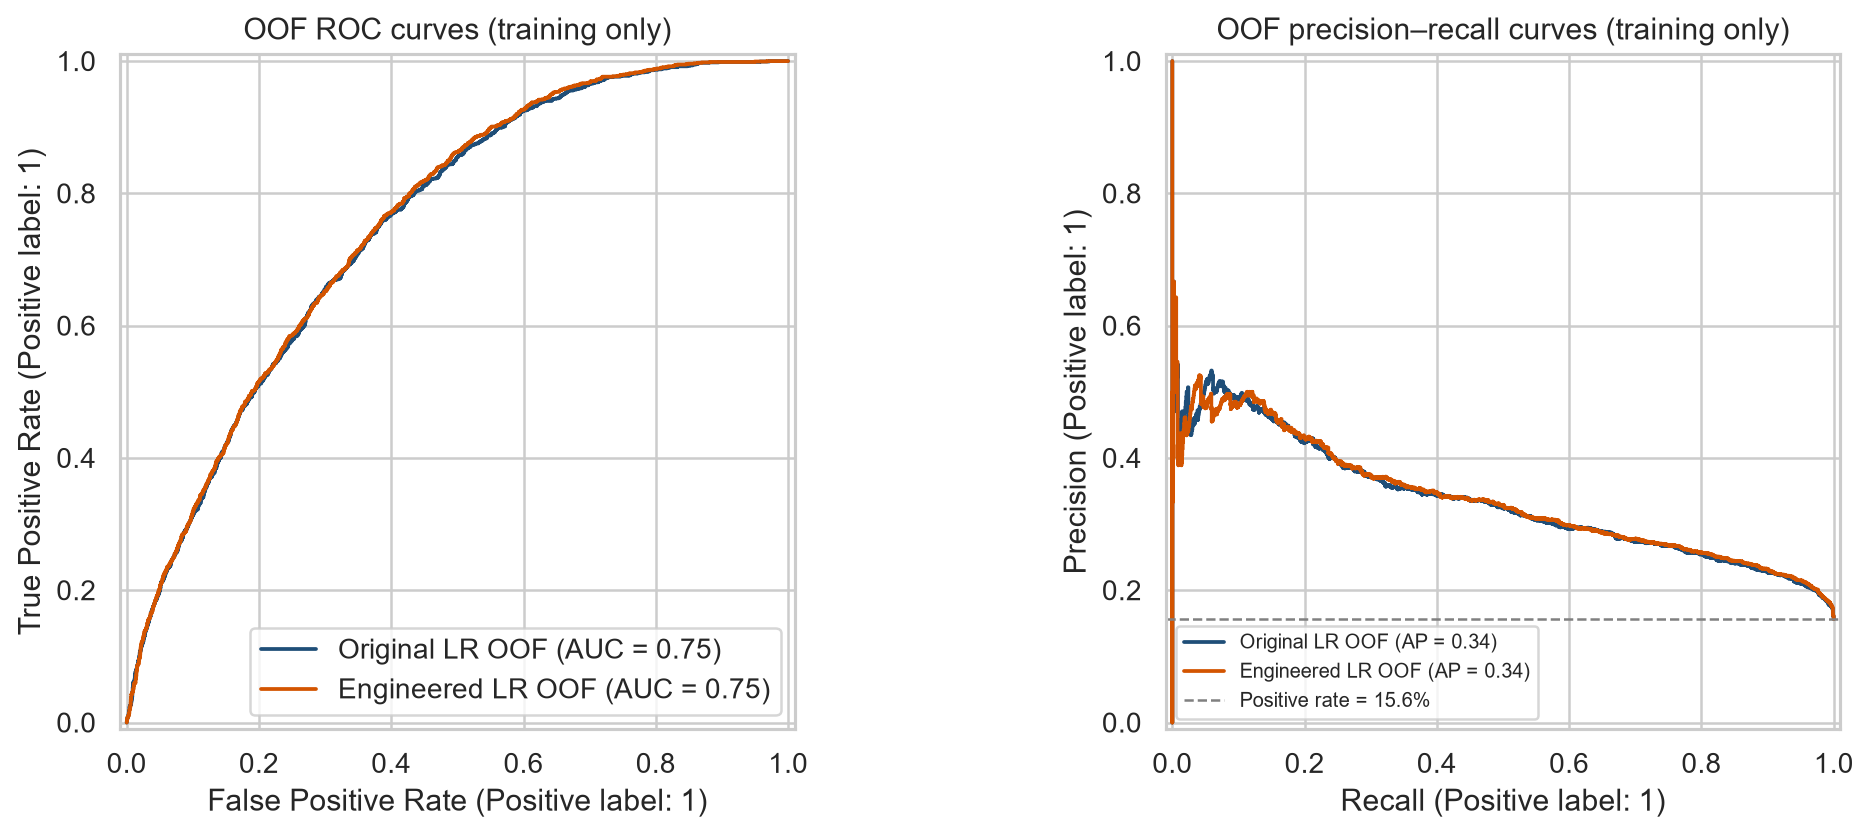

In [7]:
display(Image(filename=str(RESULTS_DIR / "04_oof_model_curves.png")))
